In [1]:
import requests
import pandas as pd
import numpy as np

pit_url = "https://api.openf1.org/v1/pit?stop_duration>0"
drivers_url = "https://api.openf1.org/v1/drivers?session_key=latest"

pit_raw = pd.DataFrame(requests.get(pit_url).json())
drivers_raw = pd.DataFrame(requests.get(drivers_url).json())[["driver_number", "name_acronym", "team_name"]].drop_duplicates("driver_number")

f1_pits = pd.merge(pit_raw, drivers_raw, on="driver_number", how="inner")
f1_pits["date"] = pd.to_datetime(f1_pits["date"])

print(f"Pulled {len(f1_pits):,} real Formula 1 stationary pit stops across {f1_pits['team_name'].nunique()} F1 Constructors!")
f1_pits[["date", "team_name", "name_acronym", "lap_number", "stop_duration", "lane_duration"]].head(10)

Pulled 1,301 real Formula 1 stationary pit stops across 11 F1 Constructors!


,date,team_name,name_acronym,lap_number,stop_duration,lane_duration
0,2024-10-20 19:10:15.705000+00:00,Williams,ALB,3,12.5,34.983
1,2024-10-20 19:32:04.880000+00:00,Cadillac,BOT,15,2.9,24.439
2,2024-10-20 19:36:58.722000+00:00,Alpine,GAS,18,6.9,28.228
3,2024-10-20 19:41:38.183000+00:00,Williams,SAI,21,2.6,23.963
4,2024-10-20 19:48:17.561000+00:00,McLaren,NOR,25,2.7,24.228
5,2024-10-20 19:49:45.492000+00:00,Ferrari,LEC,26,2.5,23.817
6,2024-10-20 19:50:21.889000+00:00,Cadillac,PER,26,2.3,23.580
7,2024-10-20 19:50:40.317000+00:00,Aston Martin,ALO,26,2.7,24.247
8,2024-10-20 19:52:06.297000+00:00,Audi,HUL,27,3.0,24.500
9,2024-10-20 19:52:33.253000+00:00,Aston Martin,STR,27,4.7,26.399


In [2]:
conditions = [
    (f1_pits["stop_duration"] >= 1.8) & (f1_pits["stop_duration"] <= 6.0),
    (f1_pits["stop_duration"] > 6.0) & (f1_pits["stop_duration"] <= 20.0)
]
choices = ["1. Competitive 4-Tire Stop (1.8s-6.0s)", "2. FIA Penalty / Front Wing Repair (6.0s-20.0s)"]

f1_pits["pit_regime"] = np.select(conditions, choices, default="3. Practice / Garage Hold (>20s)")
f1_pits["pit_transit_loss"] = round(f1_pits["lane_duration"] - f1_pits["stop_duration"], 2)

regime_audit = pd.DataFrame({
    "stops": f1_pits["pit_regime"].value_counts(),
    "share_pct": round(f1_pits["pit_regime"].value_counts(normalize=True) * 100, 1)
})

race_stops = f1_pits[f1_pits["pit_regime"] == "1. Competitive 4-Tire Stop (1.8s-6.0s)"].copy()
print(f"Isolated {len(race_stops):,} competitive 4-tire F1 pit stops for Constructor Crew Benchmarking!")
regime_audit

Isolated 1,150 competitive 4-tire F1 pit stops for Constructor Crew Benchmarking!


,stops,share_pct
pit_regime,,
1. Competitive 4-Tire Stop (1.8s-6.0s),1150,88.4
2. FIA Penalty / Front Wing Repair (6.0s-20.0s),132,10.1
3. Practice / Garage Hold (>20s),19,1.5


In [3]:
race_stops["is_elite_sub_2_5"] = race_stops["stop_duration"] <= 2.5
race_stops["is_sla_breach_over_3_5"] = race_stops["stop_duration"] > 3.5

constructor_leaderboard = race_stops.groupby("team_name").agg(
    total_stops=("stop_duration", "count"),
    fastest_stop_sec=("stop_duration", "min"),
    median_stop_sec=("stop_duration", "median"),
    mean_stop_sec=("stop_duration", "mean"),
    iqr_consistency_sec=("stop_duration", lambda x: x.quantile(0.75) - x.quantile(0.25)),
    elite_sub_2_5_pct=("is_elite_sub_2_5", lambda x: x.mean() * 100),
    sla_breach_over_3_5_pct=("is_sla_breach_over_3_5", lambda x: x.mean() * 100)
).round(2).sort_values("median_stop_sec")

constructor_leaderboard

,total_stops,fastest_stop_sec,median_stop_sec,mean_stop_sec,iqr_consistency_sec,elite_sub_2_5_pct,sla_breach_over_3_5_pct
team_name,,,,,,,
Ferrari,140,2.0,2.5,2.61,0.60,57.86,6.43
Racing Bulls,87,2.0,2.5,2.80,0.60,51.72,10.34
Audi,110,2.1,2.6,2.87,0.78,40.00,12.73
Mercedes,122,2.2,2.6,2.73,0.50,49.18,6.56
Red Bull Racing,81,2.2,2.6,2.85,0.60,45.68,11.11
McLaren,122,1.8,2.7,2.98,1.08,42.62,19.67
Aston Martin,119,2.1,2.8,3.02,0.60,20.17,18.49
Williams,131,2.1,2.8,3.08,0.70,22.90,19.85
Alpine,127,2.1,2.9,3.13,0.70,14.96,21.26


Exported F1 Pit Crew Benchmark CSVs for Tableau & GitHub!


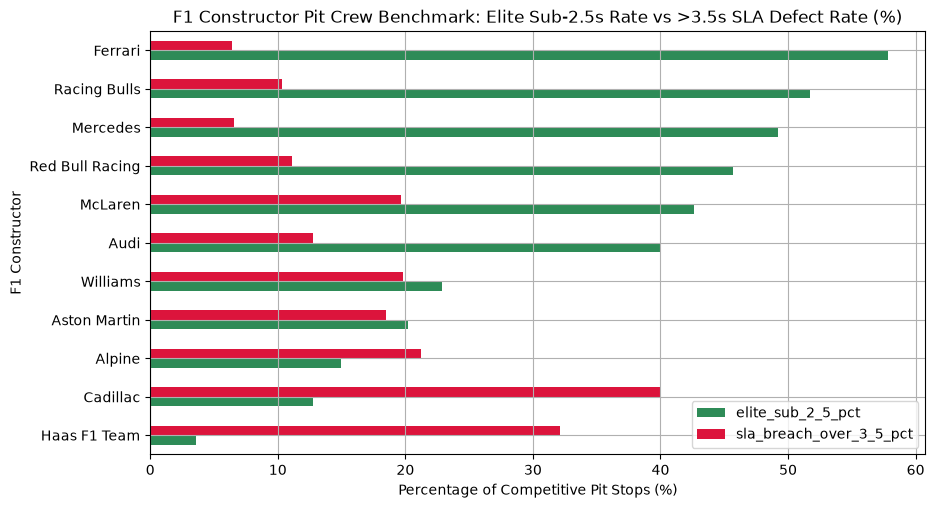

In [4]:
plot_df = constructor_leaderboard.sort_values("elite_sub_2_5_pct", ascending=True)

plot_df[["elite_sub_2_5_pct", "sla_breach_over_3_5_pct"]].plot(
    kind="barh",
    color=["seagreen", "crimson"],
    title="F1 Constructor Pit Crew Benchmark: Elite Sub-2.5s Rate vs >3.5s SLA Defect Rate (%)",
    xlabel="Percentage of Competitive Pit Stops (%)",
    ylabel="F1 Constructor",
    grid=True,
    figsize=(10, 5.5)
)

constructor_leaderboard.reset_index().to_csv("f1_constructor_pit_leaderboard.csv", index=False)
race_stops.to_csv("f1_clean_race_pit_stops.csv", index=False)
print("Exported F1 Pit Crew Benchmark CSVs for Tableau & GitHub!")